## Final figures and tables 

In [2]:
from pathlib import Path
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

T0 = time.perf_counter()

ROOT = Path("..").resolve()          # notebook está en /notebooks
FIG = ROOT / "paper" / "figures"
TAB = ROOT / "paper" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

TEST_ORDER = ["C2ST-Linear", "C2ST-RBF", "Energy", "MMD", "Sinkhorn"]
PREV_ORDER = [0.10, 0.30, 0.60]

def col(df, *names):
    """Return first matching column, case/punctuation insensitive."""
    norm = {re.sub(r"[^a-z0-9]", "", c.lower()): c for c in df.columns}
    for n in names:
        k = re.sub(r"[^a-z0-9]", "", n.lower())
        if k in norm:
            return norm[k]
    raise KeyError(f"None of {names} found.\nColumns: {list(df.columns)}")

def norm_test(x):
    s = str(x).lower().replace("_","-").replace(" ","-")
    if "linear" in s: return "C2ST-Linear"
    if "rbf" in s: return "C2ST-RBF"
    if "energy" in s: return "Energy"
    if "mmd" in s: return "MMD"
    if "sink" in s: return "Sinkhorn"
    return str(x)

def norm_prev(x):
    x = float(x)
    return x / 100 if x > 1 else x

print("ROOT:", ROOT)

ROOT: /Users/jessica/fidelity-metric-lab


### Figure 1 - observed empirical power

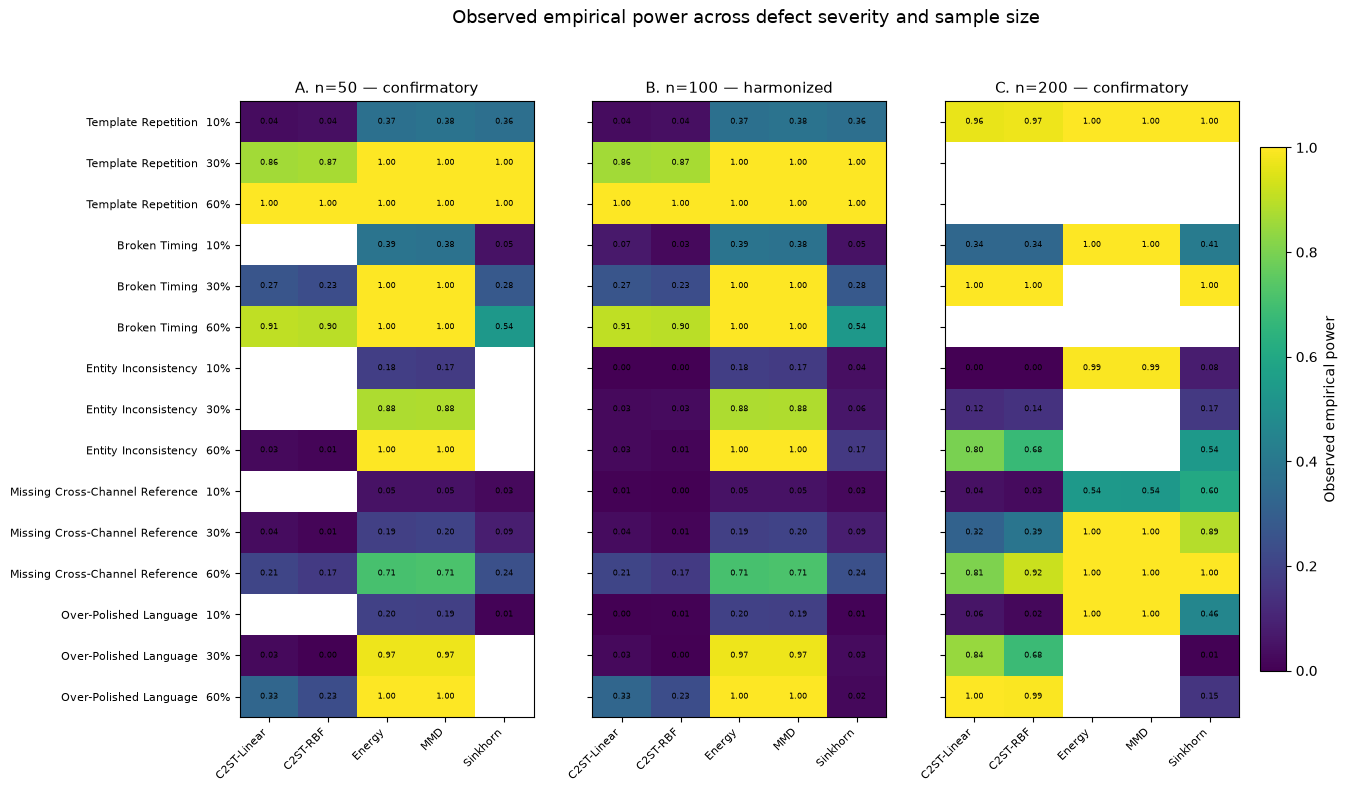

Saved: /Users/jessica/fidelity-metric-lab/paper/figures/Figure_1_observed_power.png


In [2]:
# --- Figure 1: observed power, N=50/100/200 ---

p_final = ROOT/"results/week12/final_observed_analysis/final_observed_power_wilson.csv"
p_h100  = ROOT/"results/week12/harmonized_analysis/combined_power_cells_harmonized_n100.csv"

a = pd.read_csv(p_final)
h = pd.read_csv(p_h100)

def standardize_power(df, forced_n=None):
    out = pd.DataFrame({
        "scenario": df[col(df,"scenario","defect","failure_mode")].astype(str),
        "prevalence": df[col(df,"prevalence","repetition","severity","defect_prevalence")].map(norm_prev),
        "test": df[col(df,"test","test_name","method")].map(norm_test),
        "power": pd.to_numeric(df[col(df,"power","observed_power","empirical_power")], errors="coerce"),
    })
    out["n"] = forced_n if forced_n is not None else pd.to_numeric(
        df[col(df,"n","sample_size","N")], errors="coerce"
    )
    return out

d = standardize_power(a)
d = pd.concat([d[d.n != 100], standardize_power(h, 100)], ignore_index=True)

scenario_order = [
    "Template Repetition",
    "Broken Timing",
    "Entity Inconsistency",
    "Missing Cross-Channel Reference",
    "Over-Polished Language",
]

# Match canonical labels without altering underlying results.
def canon_scenario(x):
    s = x.lower()
    if "template" in s: return "Template Repetition"
    if "broken" in s or "timing" in s: return "Broken Timing"
    if "entity" in s: return "Entity Inconsistency"
    if "missing" in s or "cross" in s: return "Missing Cross-Channel Reference"
    if "polish" in s: return "Over-Polished Language"
    return x

d["scenario"] = d["scenario"].map(canon_scenario)
d = d[d.prevalence.isin(PREV_ORDER)]

rows = pd.MultiIndex.from_product(
    [scenario_order, PREV_ORDER], names=["scenario","prevalence"]
)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 8), sharey=True)

im = None
for ax, N, title in zip(
    axes,
    [50,100,200],
    ["A. n=50 — confirmatory",
     "B. n=100 — harmonized",
     "C. n=200 — confirmatory"]
):
    x = (d[d.n == N]
         .pivot_table(index=["scenario","prevalence"],
                      columns="test", values="power", aggfunc="first")
         .reindex(index=rows, columns=TEST_ORDER))

    arr = np.ma.masked_invalid(x.to_numpy(float))
    im = ax.imshow(arr, vmin=0, vmax=1, aspect="auto")

    ax.set_title(title, fontsize=11)
    ax.set_xticks(range(len(TEST_ORDER)))
    ax.set_xticklabels(TEST_ORDER, rotation=45, ha="right", fontsize=8)

    if ax is axes[0]:
        ax.set_yticks(range(len(rows)))
        ax.set_yticklabels(
            [f"{s}  {int(p*100)}%" for s,p in rows], fontsize=8
        )

    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            if not arr.mask[i,j]:
                ax.text(j, i, f"{arr[i,j]:.2f}",
                        ha="center", va="center", fontsize=6)

fig.colorbar(im, ax=axes, label="Observed empirical power",
             fraction=.025, pad=.02)
fig.suptitle("Observed empirical power across defect severity and sample size",
             y=.995, fontsize=13)
plt.savefig(FIG/"Figure_1_observed_power.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", FIG/"Figure_1_observed_power.png")

### Table 1 — paired contrasts

In [3]:
# --- Table 1: selected paired contrasts ---

src = ROOT/"results/week12/final_observed_analysis/selected_paired_contrasts.csv"
t = pd.read_csv(src)

# Preserve numerical values exactly; only clean column presentation/order.
preferred = [
    "scenario","prevalence","n",
    "test_a","test_b",
    "power_a","power_b","power_difference",
    "n01","n10",
    "p_value","p_adjusted"
]

lookup = {re.sub(r"[^a-z0-9]","",c.lower()): c for c in t.columns}
keep = []
for x in preferred:
    k = re.sub(r"[^a-z0-9]","",x.lower())
    if k in lookup:
        keep.append(lookup[k])

out = t[keep] if keep else t.copy()

out.to_csv(TAB/"Table_1_paired_contrasts.csv", index=False)

display(out)
print("Saved:", TAB/"Table_1_paired_contrasts.csv")

,scenario,N,test_a,test_b,p_value
0,Entity Inconsistency,200,C2ST-Linear,MMD,2.489206e-60
1,Entity Inconsistency,200,C2ST-RBF,MMD,2.489206e-60
2,Over-Polished Language,200,C2ST-Linear,MMD,2.548947e-57
3,Broken Timing,200,C2ST-Linear,MMD,1.836710e-40


Saved: /Users/jessica/fidelity-metric-lab/paper/tables/Table_1_paired_contrasts.csv


### Figure 2 — Encoder robustness: MiniLM vs BGE

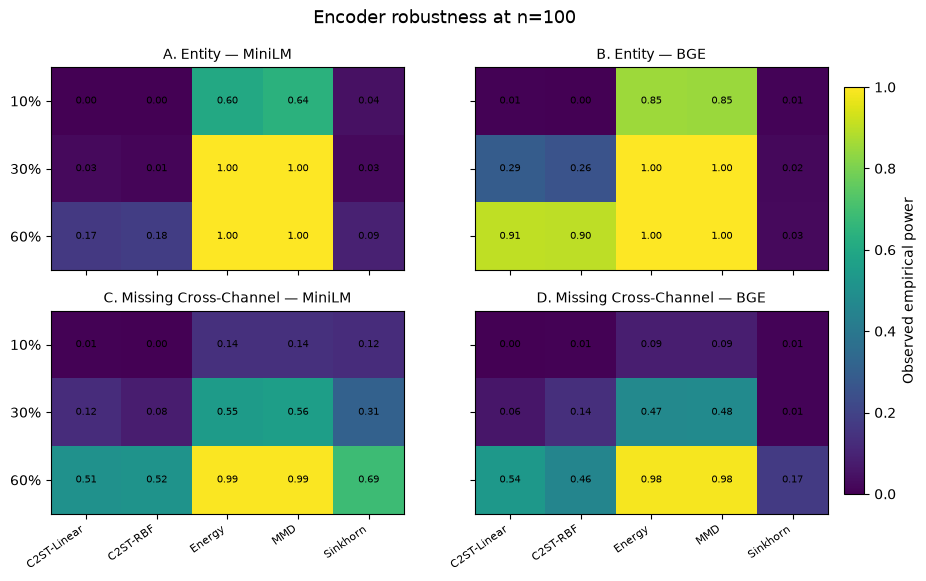

Source: /Users/jessica/fidelity-metric-lab/results/week12/final_reporting/bge_vs_minilm_n100.csv
Saved: /Users/jessica/fidelity-metric-lab/paper/figures/Figure_2_encoder_robustness.png


In [4]:
# --- Figure 2: MiniLM vs BGE robustness ---

paths = [
    ROOT/"results/week12/final_reporting/bge_vs_minilm_n100.csv",
    ROOT/"results/week13/bge_confirmatory/analysis/bge_vs_minilm_n100.csv",
]
src = next(p for p in paths if p.exists())
b = pd.read_csv(src)

scenario_c = col(b,"scenario","defect","failure_mode")
prev_c     = col(b,"prevalence","repetition","severity")
test_c     = col(b,"test","test_name","method")

base = pd.DataFrame({
    "scenario": b[scenario_c].astype(str),
    "prevalence": b[prev_c].map(norm_prev),
    "test": b[test_c].map(norm_test),
})

# Supports either wide MiniLM/BGE columns OR long encoder/power format.
try:
    minilm_c = col(b,"minilm_power","power_minilm","minilm")
    bge_c    = col(b,"bge_power","power_bge","bge")
    q = pd.concat([
        base.assign(encoder="MiniLM",
                    power=pd.to_numeric(b[minilm_c], errors="coerce")),
        base.assign(encoder="BGE",
                    power=pd.to_numeric(b[bge_c], errors="coerce"))
    ])
except KeyError:
    enc_c   = col(b,"encoder","embedding","representation")
    power_c = col(b,"power","observed_power","empirical_power")
    q = base.assign(
        encoder=b[enc_c].astype(str),
        power=pd.to_numeric(b[power_c], errors="coerce")
    )
    q["encoder"] = np.where(
        q.encoder.str.lower().str.contains("bge"), "BGE", "MiniLM"
    )

def short_scenario(x):
    s=x.lower()
    if "entity" in s: return "Entity"
    if "missing" in s or "cross" in s: return "Missing Cross-Channel"
    return x

q["scenario"] = q.scenario.map(short_scenario)

panels = [
    ("Entity","MiniLM","A. Entity — MiniLM"),
    ("Entity","BGE","B. Entity — BGE"),
    ("Missing Cross-Channel","MiniLM","C. Missing Cross-Channel — MiniLM"),
    ("Missing Cross-Channel","BGE","D. Missing Cross-Channel — BGE"),
]

fig, axes = plt.subplots(2,2,figsize=(10.5,5.8),
                         sharex=True, sharey=True)

for ax,(sc,enc,title) in zip(axes.flat, panels):
    z = (q[(q.scenario==sc)&(q.encoder==enc)]
         .pivot_table(index="prevalence",columns="test",
                      values="power",aggfunc="first")
         .reindex(index=PREV_ORDER, columns=TEST_ORDER))

    arr=np.ma.masked_invalid(z.to_numpy(float))
    im=ax.imshow(arr,vmin=0,vmax=1,aspect="auto")
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(5))
    ax.set_xticklabels(TEST_ORDER,rotation=35,ha="right",fontsize=8)
    ax.set_yticks(range(3))
    ax.set_yticklabels(["10%","30%","60%"])

    for i in range(3):
        for j in range(5):
            if not arr.mask[i,j]:
                ax.text(j,i,f"{arr[i,j]:.2f}",
                        ha="center",va="center",fontsize=7)

fig.colorbar(im,ax=axes,label="Observed empirical power",
             fraction=.025,pad=.02)
fig.suptitle("Encoder robustness at n=100", fontsize=13)
plt.savefig(FIG/"Figure_2_encoder_robustness.png",
            dpi=300,bbox_inches="tight")
plt.show()

print("Source:", src)
print("Saved:", FIG/"Figure_2_encoder_robustness.png")

### Figure 3 — Diagnostic mechanisms

In [4]:
# ============================================================
# PANEL A — Sinkhorn observed-minus-permutation-null
# Robust parser for existing Week 7 CSVs
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("..").resolve()
W7 = ROOT / "results" / "week7"

gap_files = sorted(W7.rglob("*sinkhorn*null_gap*.csv"))

print(f"Found {len(gap_files)} Sinkhorn null-gap files:\n")
for f in gap_files:
    tmp = pd.read_csv(f)
    print(f"{f.name}")
    print("   columns:", list(tmp.columns))

if not gap_files:
    raise FileNotFoundError(
        "No *sinkhorn*null_gap*.csv files found under results/week7/"
    )


def norm_name(x):
    return (
        str(x).lower()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
        .replace(".", "")
    )


def detect_prevalence_column(df):
    # First: identify by column name
    keywords = [
        "prevalence", "severity", "fraction", "proportion",
        "defectrate", "corruption", "defectfraction",
        "affectedfraction", "rate"
    ]

    for c in df.columns:
        n = norm_name(c)
        if any(k in n for k in keywords):
            vals = pd.to_numeric(df[c], errors="coerce")
            if vals.notna().any():
                return c

    # Second: identify numerically from values ~ 10/30/60 or .1/.3/.6
    allowed = {0.1, 0.3, 0.6, 10.0, 30.0, 60.0}

    for c in df.columns:
        vals = pd.to_numeric(df[c], errors="coerce").dropna()

        if len(vals):
            unique = set(np.round(vals.unique(), 6))
            if unique and unique.issubset(allowed):
                return c

    return None


def detect_gap(df):
    # Case 1: file already contains a gap / delta column
    preferred = []

    for c in df.columns:
        n = norm_name(c)

        if (
            "gap" in n
            or "delta" in n
            or "minusnull" in n
            or ("observed" in n and "null" in n)
        ):
            if pd.to_numeric(df[c], errors="coerce").notna().any():
                preferred.append(c)

    if preferred:
        return pd.to_numeric(df[preferred[0]], errors="coerce"), preferred[0]

    # Case 2: calculate observed - null mean ourselves
    observed_candidates = []
    null_candidates = []

    for c in df.columns:
        n = norm_name(c)

        if "observ" in n and "null" not in n:
            if pd.to_numeric(df[c], errors="coerce").notna().any():
                observed_candidates.append(c)

        if "null" in n and (
            "mean" in n or
            "average" in n or
            "center" in n or
            "stat" in n
        ):
            if pd.to_numeric(df[c], errors="coerce").notna().any():
                null_candidates.append(c)

    if observed_candidates and null_candidates:
        obs = observed_candidates[0]
        nul = null_candidates[0]

        gap = (
            pd.to_numeric(df[obs], errors="coerce")
            - pd.to_numeric(df[nul], errors="coerce")
        )

        return gap, f"{obs} - {nul}"

    return None, None


def scenario_from_filename(path):
    s = path.stem.lower()

    if "template" in s:
        return "Template Repetition"

    if "broken" in s or "timing" in s:
        return "Broken Timing"

    if "entity" in s:
        return "Entity Inconsistency"

    if (
        "missing" in s
        or "cross" in s
        or "reference" in s
    ):
        return "Missing Cross-Channel Reference"

    if "polish" in s:
        return "Over-Polished Language"

    return path.stem


sinkhorn_parts = []

print("\nINTERPRETATION\n" + "-"*60)

for f in gap_files:

    df = pd.read_csv(f)

    prev_col = detect_prevalence_column(df)
    gap, gap_source = detect_gap(df)

    print(f"\n{f.name}")
    print(" prevalence column:", prev_col)
    print(" gap source:", gap_source)

    if prev_col is None or gap is None:
        print(" -> skipped")
        continue

    prev = pd.to_numeric(df[prev_col], errors="coerce")

    # Convert 10,30,60 -> .10,.30,.60
    prev = np.where(prev > 1, prev / 100, prev)

    part = pd.DataFrame({
        "scenario": scenario_from_filename(f),
        "prevalence": prev,
        "gap": gap
    })

    part = part.dropna()

    if len(part):
        sinkhorn_parts.append(part)
        print(" -> accepted")
    else:
        print(" -> no usable rows")


if not sinkhorn_parts:
    raise ValueError(
        "\nThe files exist, but the automatic parser still could not "
        "identify the required columns.\n"
        "Look at the printed column names above."
    )


sinkhorn = pd.concat(
    sinkhorn_parts,
    ignore_index=True
)

sinkhorn = (
    sinkhorn
    .groupby(
        ["scenario", "prevalence"],
        as_index=False
    )["gap"]
    .mean()
    .sort_values(
        ["scenario", "prevalence"]
    )
)

print("\nFINAL DATA FOR PANEL A")
display(sinkhorn)

Found 2 Sinkhorn null-gap files:

broken_timing_formal_sinkhorn_null_gap.csv
   columns: ['severity', 'mean_statistic', 'mean_null', 'mean_obs_minus_null', 'std_obs_minus_null', 'power']
template_formal_sinkhorn_null_gap.csv
   columns: ['severity', 'mean_statistic', 'mean_null', 'mean_obs_minus_null', 'std_obs_minus_null', 'power']

INTERPRETATION
------------------------------------------------------------

broken_timing_formal_sinkhorn_null_gap.csv
 prevalence column: severity
 gap source: mean_obs_minus_null
 -> accepted

template_formal_sinkhorn_null_gap.csv
 prevalence column: severity
 gap source: mean_obs_minus_null
 -> accepted

FINAL DATA FOR PANEL A


,scenario,prevalence,gap
0,Broken Timing,0.1,0.000215
1,Broken Timing,0.3,0.019161
2,Broken Timing,0.6,0.068373
3,Template Repetition,0.1,0.043676
4,Template Repetition,0.3,0.145941
5,Template Repetition,0.6,0.302790


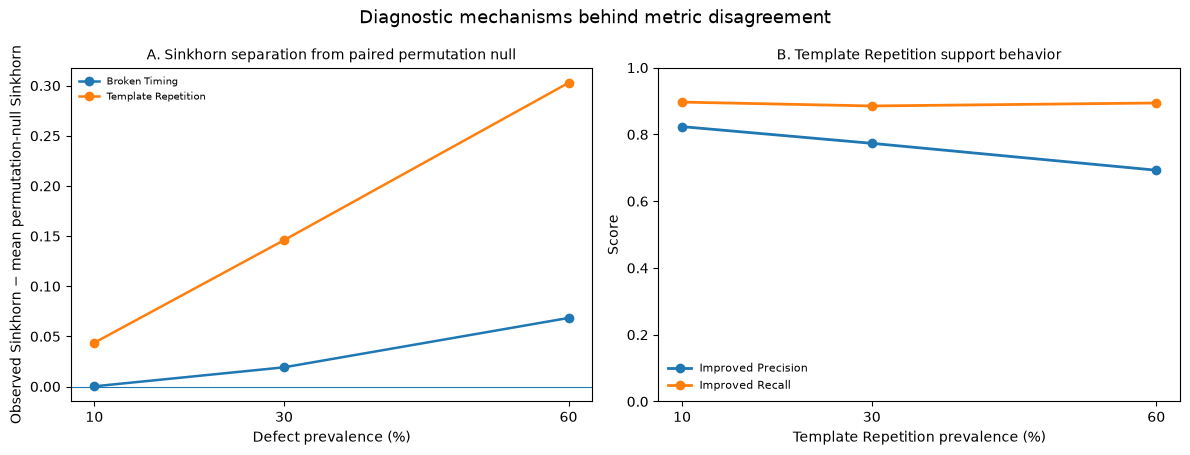

Sinkhorn files:
 • broken_timing_formal_sinkhorn_null_gap.csv
 • template_formal_sinkhorn_null_gap.csv

IPR source: ipr_five_defects_compact.csv

Saved: /Users/jessica/fidelity-metric-lab/paper/figures/Figure_3_diagnostic_mechanisms.png


In [5]:
# ============================================================
# PANEL B — Template Repetition Improved Precision / Recall
# ============================================================

ipr_candidates = [
    W7 / "ipr_five_defects_compact.csv",
    W7 / "ipr_five_defects_summary.csv",
    W7 / "ipr_five_defects_prevalence.csv",
    W7 / "ipr_repetition_stress.csv",
    W7 / "ipr_template_reference_comparison.csv",
]

ipr_file = next((p for p in ipr_candidates if p.exists()), None)

if ipr_file is None:
    hits = (
        list(W7.rglob("ipr_five_defects*.csv"))
        + list(W7.rglob("ipr_repetition_stress.csv"))
    )
    if not hits:
        raise FileNotFoundError(
            "No suitable IPR diagnostic file found in results/week7/"
        )
    ipr_file = hits[0]

ipr_raw = pd.read_csv(ipr_file)

scenario_col = find_col(
    ipr_raw,
    ["scenario", "defect", "failure_mode"]
)

# Keep only Template Repetition if the file contains all defects.
if scenario_col is not None:
    mask = (
        ipr_raw[scenario_col]
        .astype(str)
        .str.lower()
        .str.contains("template|repetition")
    )
    if mask.any():
        ipr_raw = ipr_raw[mask].copy()

prev_col = find_col(
    ipr_raw,
    ["prevalence", "severity", "defect_prevalence",
     "corruption_fraction", "fraction"]
)

precision_col = find_col(
    ipr_raw,
    ["improved_precision", "precision",
     "ipr_precision", "mean_precision"]
)

recall_col = find_col(
    ipr_raw,
    ["improved_recall", "recall",
     "ipr_recall", "mean_recall"]
)

if prev_col is None or precision_col is None or recall_col is None:
    raise ValueError(
        f"Could not identify IPR columns in {ipr_file.name}.\n"
        f"Columns found: {list(ipr_raw.columns)}"
    )

ipr = pd.DataFrame({
    "prevalence":
        pd.to_numeric(ipr_raw[prev_col], errors="coerce"),
    "precision":
        pd.to_numeric(ipr_raw[precision_col], errors="coerce"),
    "recall":
        pd.to_numeric(ipr_raw[recall_col], errors="coerce"),
})

ipr["prevalence"] = np.where(
    ipr["prevalence"] > 1,
    ipr["prevalence"] / 100,
    ipr["prevalence"]
)

ipr = (
    ipr.dropna()
       .groupby("prevalence", as_index=False)
       [["precision", "recall"]]
       .mean()
       .sort_values("prevalence")
)

# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.6)
)

# ---------- Panel A ----------
scenario_order = [
    "Entity Inconsistency",
    "Over-Polished Language",
    "Missing Cross-Channel Reference",
    "Broken Timing",
    "Template Repetition",
]

for scenario in scenario_order:
    d = sinkhorn[sinkhorn["scenario"] == scenario].sort_values("prevalence")

    if len(d):
        axes[0].plot(
            d["prevalence"] * 100,
            d["gap"],
            marker="o",
            linewidth=1.8,
            label=scenario
        )

axes[0].axhline(0, linewidth=0.8)
axes[0].set_xticks([10, 30, 60])
axes[0].set_xlabel("Defect prevalence (%)")
axes[0].set_ylabel(
    r"Observed Sinkhorn $-$ mean permutation-null Sinkhorn"
)
axes[0].set_title(
    "A. Sinkhorn separation from paired permutation null",
    fontsize=10
)
axes[0].legend(
    fontsize=7,
    frameon=False
)

# ---------- Panel B ----------
axes[1].plot(
    ipr["prevalence"] * 100,
    ipr["precision"],
    marker="o",
    linewidth=2,
    label="Improved Precision"
)

axes[1].plot(
    ipr["prevalence"] * 100,
    ipr["recall"],
    marker="o",
    linewidth=2,
    label="Improved Recall"
)

axes[1].set_xticks([10, 30, 60])
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Template Repetition prevalence (%)")
axes[1].set_ylabel("Score")
axes[1].set_title(
    "B. Template Repetition support behavior",
    fontsize=10
)
axes[1].legend(
    frameon=False,
    fontsize=8
)

fig.suptitle(
    "Diagnostic mechanisms behind metric disagreement",
    fontsize=13
)

plt.tight_layout()

outfile = OUT / "Figure_3_diagnostic_mechanisms.png"

plt.savefig(
    outfile,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Sinkhorn files:")
for f in gap_files:
    print(" •", f.name)

print("\nIPR source:", ipr_file.name)
print("\nSaved:", outfile)

In [6]:
# final check
outputs = [
    FIG/"Figure_1_observed_power.png",
    TAB/"Table_1_paired_contrasts.csv",
    FIG/"Figure_2_encoder_robustness.png",
    FIG/"Figure_3_diagnostic_mechanisms.png",
]

for p in outputs:
    print("✓" if p.exists() else "✗", p.relative_to(ROOT))

print(f"\nElapsed: {time.perf_counter()-T0:.1f} s")

✓ paper/figures/Figure_1_observed_power.png
✓ paper/tables/Table_1_paired_contrasts.csv
✓ paper/figures/Figure_2_encoder_robustness.png
✓ paper/figures/Figure_3_diagnostic_mechanisms.png

Elapsed: 9852.9 s


In [7]:
from pathlib import Path
import pandas as pd

ROOT = Path("..").resolve()

files = {
    "Harmonized n=100": (
        ROOT / "results/week12/harmonized_n100/harmonized_n100_power_runs.csv",
        ROOT / "results/week12/harmonized_n100/harmonized_n100_clean_null_runs.csv",
    ),
    "BGE robustness": (
        ROOT / "results/week13/bge_confirmatory/bge_power_runs.csv",
        ROOT / "results/week13/bge_confirmatory/bge_null_runs.csv",
    ),
}

def runtime_col(df):
    for c in ["runtime", "runtime_seconds"]:
        if c in df.columns:
            return c
    raise KeyError(f"No runtime column found. Columns: {list(df.columns)}")

def fmt(sec):
    sec = int(round(sec))
    h, rem = divmod(sec, 3600)
    m, s = divmod(rem, 60)
    return f"{h} h {m} min {s} s"

for name, (power_file, null_file) in files.items():
    power = pd.read_csv(power_file)
    null = pd.read_csv(null_file)

    rp = power[runtime_col(power)].sum()
    rn = null[runtime_col(null)].sum()
    total = rp + rn

    print(f"\n{name}")
    print(f"  Power runtime: {rp:.2f} s  ({fmt(rp)})")
    print(f"  Null runtime:  {rn:.2f} s  ({fmt(rn)})")
    print(f"  Total runtime: {total:.2f} s  ({fmt(total)})")


Harmonized n=100
  Power runtime: 4511.33 s  (1 h 15 min 11 s)
  Null runtime:  930.40 s  (0 h 15 min 30 s)
  Total runtime: 5441.74 s  (1 h 30 min 42 s)

BGE robustness
  Power runtime: 1171.16 s  (0 h 19 min 31 s)
  Null runtime:  206.50 s  (0 h 3 min 26 s)
  Total runtime: 1377.66 s  (0 h 22 min 58 s)


In [8]:
from pathlib import Path
import pandas as pd

ROOT = Path("..").resolve()
W7 = ROOT / "results/week7"

for pattern in ["**/ipr_known_answer_summary.csv",
                "**/ipr_known_answer_checks.csv",
                "**/ipr_k_sensitivity_summary.csv"]:
    for f in W7.glob(pattern):
        print(f"\n--- {f.name} ---")
        display(pd.read_csv(f))


--- ipr_known_answer_summary.csv ---


,condition,repetitions,mean_precision,std_precision,mean_recall,std_recall,precision_change_vs_matched,recall_change_vs_matched
0,invented_mass,30,0.763111,0.026333,0.956222,0.018440,-0.188333,-0.006778
1,matched,30,0.951444,0.014561,0.963000,0.011853,0.000000,0.000000
2,mode_drop,30,0.954111,0.020467,0.575667,0.026669,0.002667,-0.387333
3,repetition,30,0.958444,0.022637,0.513444,0.053034,0.007000,-0.449556



--- ipr_known_answer_checks.csv ---


,check,passed
0,Matched precision is high,True
1,Matched recall is high,True
2,Mode dropping keeps precision high,True
3,Mode dropping lowers recall,True
4,Invented mass lowers precision,True
5,Invented mass keeps recall high,True
6,Repetition keeps precision high,True
7,Repetition lowers recall,True



--- ipr_k_sensitivity_summary.csv ---


,k,condition,mean_precision,mean_recall
0,2,invented_mass,0.718333,0.907667
1,2,matched,0.896000,0.922667
2,2,mode_drop,0.904333,0.545667
3,2,repetition,0.903333,0.000000
4,3,invented_mass,0.758333,0.953667
5,3,matched,0.947667,0.962000
6,3,mode_drop,0.953000,0.572333
7,3,repetition,0.952667,0.508667
8,5,invented_mass,0.777667,0.979333
9,5,matched,0.977000,0.983667


#### Figure F1 — Full Sinkhorn observed-minus-null

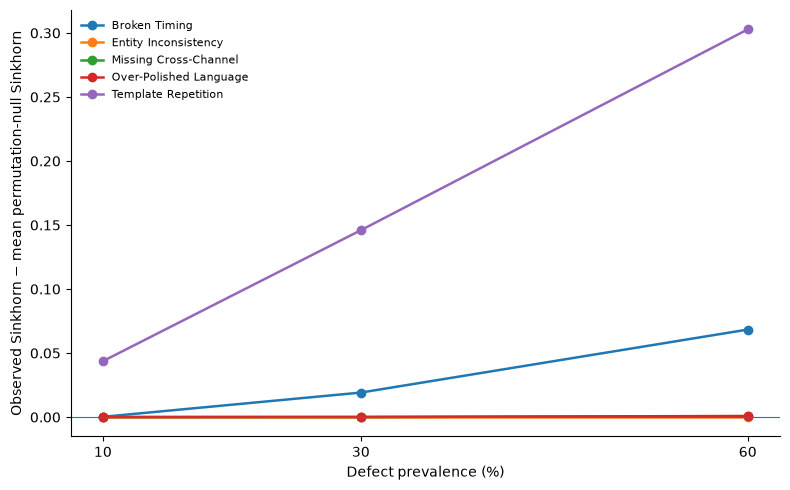

In [9]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
W7 = ROOT / "results/week7"
OUT = ROOT / "paper/figures"
OUT.mkdir(parents=True, exist_ok=True)

f = W7 / "comparison/week7_sinkhorn_observed_minus_null.csv"
df = pd.read_csv(f)

df["severity"] = pd.to_numeric(df["severity"])
df["prevalence"] = df["severity"].apply(lambda x: x*100 if x <= 1 else x)

fig, ax = plt.subplots(figsize=(8,5))

for defect, g in df.groupby("defect"):
    g = g.sort_values("prevalence")
    ax.plot(
        g["prevalence"],
        g["sinkhorn_obs_minus_null"],
        marker="o",
        linewidth=1.8,
        label=defect
    )

ax.axhline(0, linewidth=0.8)
ax.set_xlabel("Defect prevalence (%)")
ax.set_ylabel("Observed Sinkhorn − mean permutation-null Sinkhorn")
ax.set_xticks([10,30,60])
ax.legend(frameon=False, fontsize=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(OUT / "Figure_F1_sinkhorn_observed_minus_null.png",
            dpi=300, bbox_inches="tight")
plt.show()

#### Figure F3 — Data-copying benchmark

In [11]:
from pathlib import Path
import pandas as pd

ROOT = Path("..").resolve()
W7 = ROOT / "results/week7"

for name in [
    "data_copying_power_summary.csv",
    "data_copying_sensitivity_summary.csv"
]:
    f = W7 / name
    df = pd.read_csv(f)

    print(f"\n--- {name} ---")
    print("Columns:", list(df.columns))
    display(df)


--- data_copying_power_summary.csv ---
Columns: ['severity', 'repetitions', 'rejections', 'rejection_rate', 'mean_p_value', 'median_p_value', 'mean_statistic', 'std_statistic', 'mean_distance_P', 'mean_distance_Q', 'mean_copied']


,severity,repetitions,rejections,rejection_rate,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_distance_P,mean_distance_Q,mean_copied
0,0.0,200,13,0.065,0.481695,0.4585,0.002375,0.029805,0.946428,0.944053,0.0
1,0.1,200,177,0.885,0.018490,0.0040,0.096646,0.028177,0.946428,0.849782,15.0
2,0.3,200,200,1.000,0.001000,0.0010,0.284114,0.025645,0.946428,0.662314,45.0
3,0.6,200,200,1.000,0.001000,0.0010,0.568110,0.022764,0.946428,0.378318,90.0



--- data_copying_sensitivity_summary.csv ---
Columns: ['severity', 'rejections', 'rejection_rate', 'mean_p_value', 'mean_statistic', 'mean_distance_Q', 'mean_copied']


,severity,rejections,rejection_rate,mean_p_value,mean_statistic,mean_distance_Q,mean_copied
0,0.1,177,0.885,0.01849,0.096646,0.849782,15.0
1,0.3,200,1.000,0.00100,0.284114,0.662314,45.0
2,0.6,200,1.000,0.00100,0.568110,0.378318,90.0


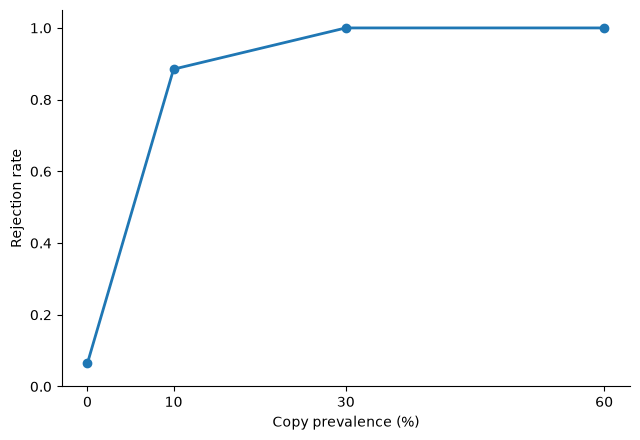

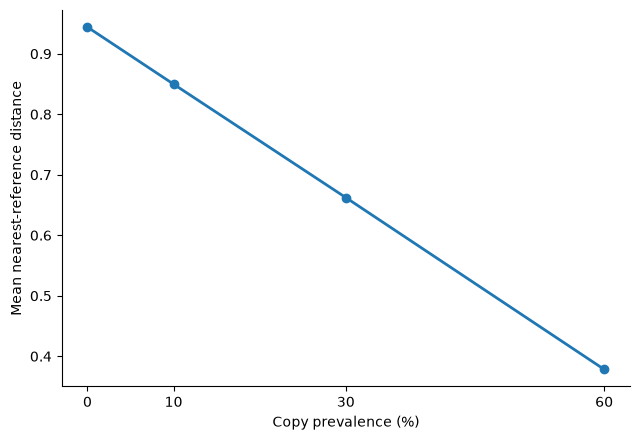

In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
W7 = ROOT / "results/week7"
OUT = ROOT / "paper/figures"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(W7 / "data_copying_power_summary.csv")
df["prevalence"] = df["severity"] * 100

# Panel A — rejection rate
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(df["prevalence"], df["rejection_rate"], marker="o", linewidth=2)
ax.set_xlabel("Copy prevalence (%)")
ax.set_ylabel("Rejection rate")
ax.set_xticks([0, 10, 30, 60])
ax.set_ylim(0, 1.05)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(OUT / "Figure_F3A_data_copying_power.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Panel B — nearest-reference distance
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(df["prevalence"], df["mean_distance_Q"], marker="o", linewidth=2)
ax.set_xlabel("Copy prevalence (%)")
ax.set_ylabel("Mean nearest-reference distance")
ax.set_xticks([0, 10, 30, 60])
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(OUT / "Figure_F3B_data_copying_distance.png",
            dpi=300, bbox_inches="tight")
plt.show()